# Mercado automotriz en La Habana — Análisis Exploratorio (EDA)

**Proyecto de Ciencia de Datos · Universidad de La Habana**

**Preguntas que responde esta fase:**
1. ¿Qué factores explican el precio de un carro en La Habana? (marca, año, zona)
3. ¿Qué segmentos de mercado existen? (clásicos, modernos, económicos…)

**Fuente de datos:** 600 anuncios de carros en La Habana scrapeados de Revolico
(`data/raw/anuncios.csv`) a través de su API GraphQL (muestra ampliada en la
revisión de la Fase 5; respaldo de la muestra original de 150 en
`data/raw/respaldo_150_2026-09-24/`).

In [1]:
# 0. Configuración general
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")          # limpiar la salida del informe
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Raíz del proyecto: funciona lanzando Jupyter desde ProyectoCD o desde notebooks/
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

# Parámetro de análisis: tasa de conversión de referencia
TASA_CUP_USD = 710          # 1 USD = 710 CUP

print("Raíz del proyecto:", RAIZ)
print("pandas", pd.__version__, "· seaborn", sns.__version__)

Raíz del proyecto: D:\Dany\ProyectoCD
pandas 3.0.6 · seaborn 0.13.2


## 1. Carga de datos

In [2]:
# 1.1 Cargar y ver la estructura
df = pd.read_csv(RAIZ / "data" / "raw" / "anuncios.csv")
print(f"Filas: {df.shape[0]}  ·  Columnas: {df.shape[1]}")
df.head()

Filas: 600  ·  Columnas: 24


,fuente,fecha,ubicacion,marca,modelo,anio,precio_original,moneda,precio_usd,combustible,...,km,descripcion,url,anuncio_id,vistas,imagenes,es_destacado,actualizado_el,pagina,total_pagina
0,anuncio,2026-09-24,"La Habana, Playa",lada,2107,NaN,6800.0,USD,6800.0,NaN,...,NaN,Venta lada 2107,https://www.revolico.com/item/venta-lada-2107-...,57663364,1,0,False,2026-09-25T00:18:35.638Z,1,50
1,anuncio,2026-09-24,"La Habana, Arroyo Naranjo",toyota,corolla automático gasolina,2018.0,18500.0,USD,18500.0,NaN,...,NaN,Toyota Corolla 2018 automático gasolina azul -...,https://www.revolico.com/item/toyota-corolla-2...,57663088,1,3,False,2026-09-24T23:58:17.615Z,1,50
2,anuncio,2026-09-24,"La Habana, Guanabacoa",lada,1600 único dueño,NaN,5000.0,USD,5000.0,NaN,...,NaN,Lada 1600. Único dueño. 5k,https://www.revolico.com/item/lada-1600-unico-...,57661916,13,4,False,2026-09-24T22:32:58.989Z,1,50
3,anuncio,2026-09-24,"La Habana, Guanabacoa",hyundai,ioniq 5,2024.0,38000.0,USD,38000.0,NaN,...,NaN,Hyundai IONIQ 5 2024,https://www.revolico.com/item/hyundai-ioniq-5-...,57661707,1,4,False,2026-09-24T22:17:40.552Z,1,50
4,anuncio,2026-09-24,"La Habana, Plaza",NaN,aprovecha,NaN,4200.0,USD,4200.0,NaN,...,NaN,Aprovecha,https://www.revolico.com/item/aprovecha-57661621,57661621,9,3,False,2026-09-24T22:10:59.643Z,1,50


In [3]:
# 1.2 Tipos de datos y valores faltantes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 24 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   fuente           600 non-null    str    
 1   fecha            600 non-null    str    
 2   ubicacion        600 non-null    str    
 3   marca            390 non-null    str    
 4   modelo           556 non-null    str    
 5   anio             321 non-null    float64
 6   precio_original  555 non-null    float64
 7   moneda           555 non-null    str    
 8   precio_usd       549 non-null    float64
 9   combustible      0 non-null      float64
 10  transmision      0 non-null      float64
 11  estado           0 non-null      float64
 12  color            0 non-null      float64
 13  notas            0 non-null      float64
 14  km               0 non-null      float64
 15  descripcion      600 non-null    str    
 16  url              600 non-null    str    
 17  anuncio_id       600 non-nu

## 2. Limpieza

Objetivos: precios numéricos, conversión de moneda a USD, marcas
normalizadas, años enteros, ubicación separada en municipio, y detección
de duplicados y valores atípicos.

In [4]:
# 2.1 Precio numérico y conversión a USD
df_limpio = df.copy()
df_limpio["precio_num"] = pd.to_numeric(df_limpio["precio_original"], errors="coerce")
df_limpio["moneda"] = df_limpio["moneda"].fillna("")

def a_usd(fila):
    """Precio en USD. CUP se convierte con la tasa de referencia; MLC/EUR ≈ 1 USD."""
    if pd.isna(fila["precio_num"]):
        return np.nan
    if fila["moneda"] == "USD":
        return fila["precio_num"]
    if fila["moneda"] == "CUP":
        return fila["precio_num"] / TASA_CUP_USD
    if fila["moneda"] in ("MLC", "EUR"):
        return fila["precio_num"]
    return np.nan

df_limpio["precio_usd"] = df_limpio.apply(a_usd, axis=1)
print("Monedas de los anuncios:")
print(df_limpio["moneda"].value_counts(dropna=False).to_string())
print("\nAnuncios con precio en USD (útiles para el análisis):",
      df_limpio["precio_usd"].notna().sum())

Monedas de los anuncios:
moneda
USD    549
        45
CUP      6

Anuncios con precio en USD (útiles para el análisis): 555


In [5]:
# 2.2 Marcas, años y municipio
df_limpio["marca"] = df_limpio["marca"].fillna("").replace("", "no identificada")
df_limpio["anio"] = pd.to_numeric(df_limpio["anio"], errors="coerce").fillna(0).astype(int)

df_limpio["municipio"] = (df_limpio["ubicacion"]
                          .str.replace("^La Habana, ?", "", regex=True)
                          .str.strip()
                          .replace("", "no especificado"))

print("Duplicados por anuncio_id:", df_limpio.duplicated("anuncio_id").sum())
print("Duplicados por url:", df_limpio.duplicated("url").sum())
print("\nMunicipios representados:", df_limpio["municipio"].nunique())

Duplicados por anuncio_id: 0
Duplicados por url: 0

Municipios representados: 15


In [6]:
# 2.3 Limpieza del modelo (los títulos traen ruido: teléfonos, palabras sueltas)
BASURA = {"venta", "en", "de", "la", "el", "los", "las", "carro", "carros",
          "auto", "autos", "usd", "cup", "mlc", "ano", "año", "km", "se",
          "vende", "precio", "llamar", "interesados", "al", "msg", "wa",
          "whatsapp", "telf", "tel", "solo", "x", "por", "para", "con",
          "y", "o", "nuevo", "nuevos", "moderno", "modernos", "importado",
          "importados", "original", "nacional", "garantia", "garantía"}

def limpiar_modelo(m):
    if not isinstance(m, str):
        return ""
    m = m.lower()
    m = re.sub(r"\b\d{6,9}\b", " ", m)            # teléfonos
    palabras = [p for p in re.split(r"[^a-z0-9áéíóúñ]+", m)
                if p and p not in BASURA]
    return " ".join(palabras[:3])

df_limpio["modelo"] = df_limpio["modelo"].map(limpiar_modelo)

In [7]:
# 2.4 Valores atípicos de precio (se revisan, no se borran a ciegas)
precios = df_limpio.dropna(subset=["precio_usd"]).copy()
q1, q3 = precios["precio_usd"].quantile([0.25, 0.75])
iqr = q3 - q1
limite = q3 + 1.5 * iqr
print(f"Q1 = {q1:,.0f} USD · Q3 = {q3:,.0f} USD · IQR = {iqr:,.0f} USD")
print(f"Límite superior (Q3 + 1.5·IQR) = {limite:,.0f} USD")
print("\nPosibles valores atípicos por encima del límite:")
out = precios[precios["precio_usd"] > limite]
if len(out):
    print(out[["marca", "modelo", "anio", "precio_usd"]].to_string(index=False))
else:
    print("Ninguno.")

Q1 = 4,500 USD · Q3 = 34,500 USD · IQR = 30,000 USD
Límite superior (Q3 + 1.5·IQR) = 79,500 USD

Posibles valores atípicos por encima del límite:
   marca             modelo  anio  precio_usd
dongfeng     voyah free 318  2026     82000.0
     bmw  x6 competition 49  2022    120000.0
     bmw x6 competitiont x6  2022    250000.0


## 3. Análisis exploratorio

Distribución de precios, marcas, relación precio–año, zonas geográficas y
visibilidad de los anuncios.

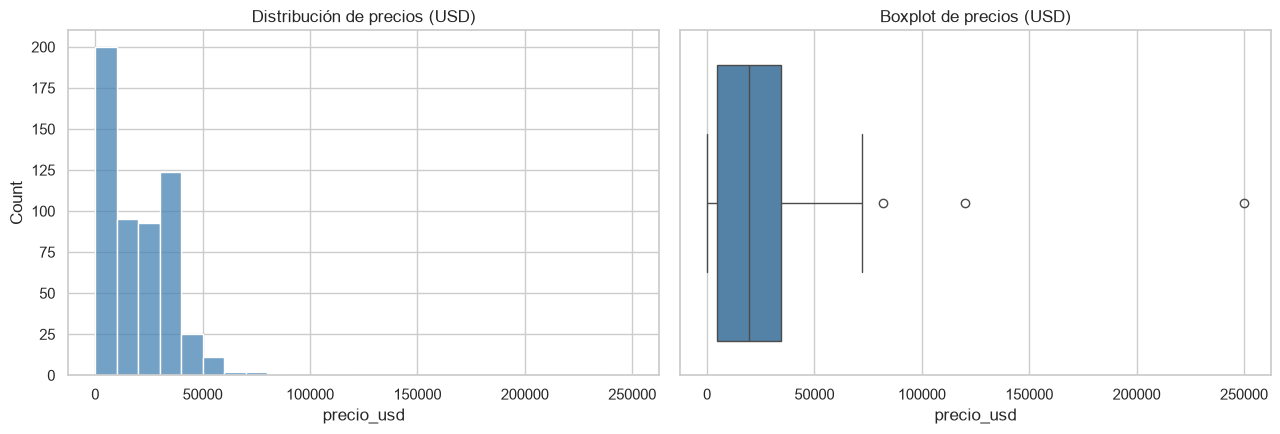

In [8]:
# 3.1 Distribución de precios
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(precios["precio_usd"], bins=25, color="steelblue", ax=axes[0])
axes[0].set_title("Distribución de precios (USD)")
sns.boxplot(x=precios["precio_usd"], color="steelblue", ax=axes[1])
axes[1].set_title("Boxplot de precios (USD)")
plt.tight_layout()
plt.savefig(RAIZ / "reports" / "fig_01_precios.png", dpi=130, bbox_inches="tight")
plt.show()

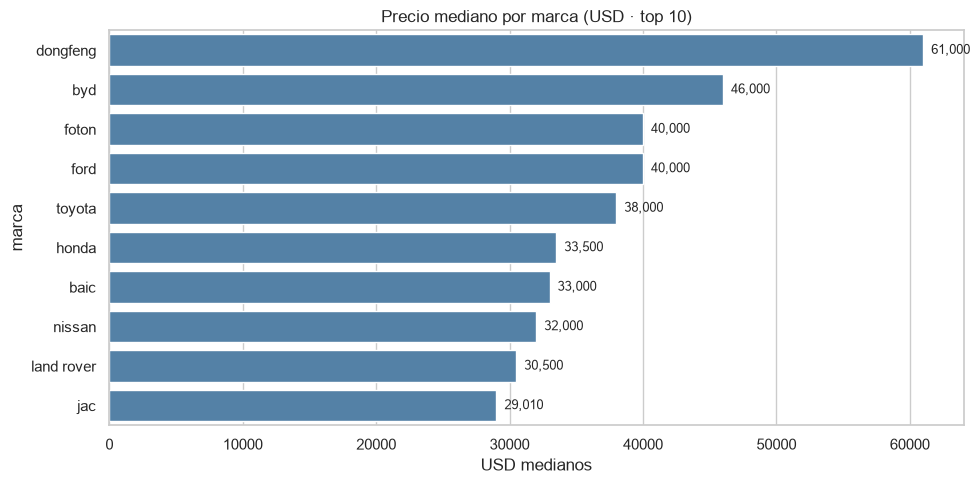

In [ ]:
# 3.3 Precio mediano por marca
mp = (precios.dropna(subset=["marca"])
      .groupby("marca")["precio_usd"].median()
      .sort_values(ascending=False).head(10))
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=mp.values, y=mp.index, color="steelblue", ax=ax)
ax.set_title("Precio mediano por marca (USD · top 10)")
ax.set_xlabel("USD medianos")
for i, v in enumerate(mp.values):
    ax.text(v, i, f"  {v:,.0f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(RAIZ / "reports" / "fig_03_precio_por_marca.png", dpi=130, bbox_inches="tight")
plt.show()

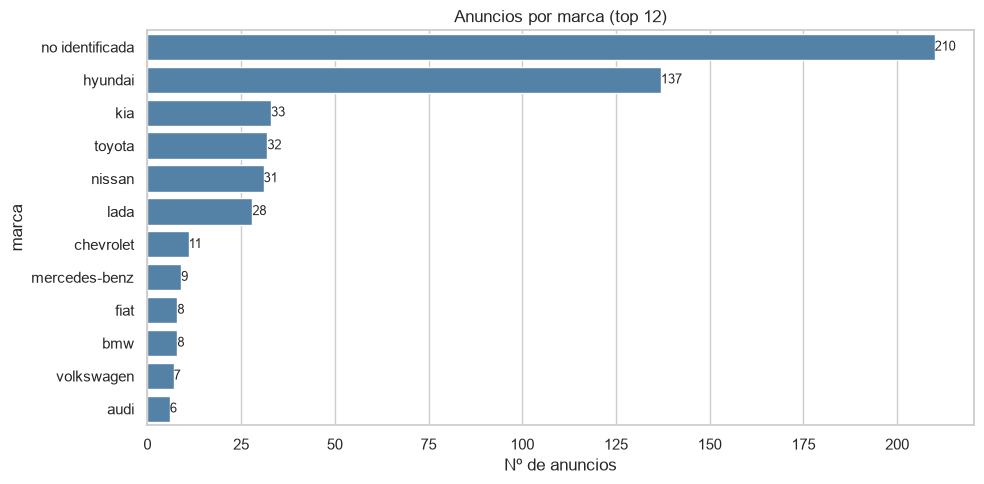

In [9]:
# 3.2 Anuncios por marca
top_marcas = df_limpio["marca"].value_counts().head(12)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=top_marcas.values, y=top_marcas.index, color="steelblue", ax=ax)
ax.set_title("Anuncios por marca (top 12)")
ax.set_xlabel("Nº de anuncios")
ax.bar_label(ax.containers[0], label_type="edge", fontsize=9)
plt.tight_layout()
plt.savefig(RAIZ / "reports" / "fig_02_anuncios_por_marca.png", dpi=130, bbox_inches="tight")
plt.show()

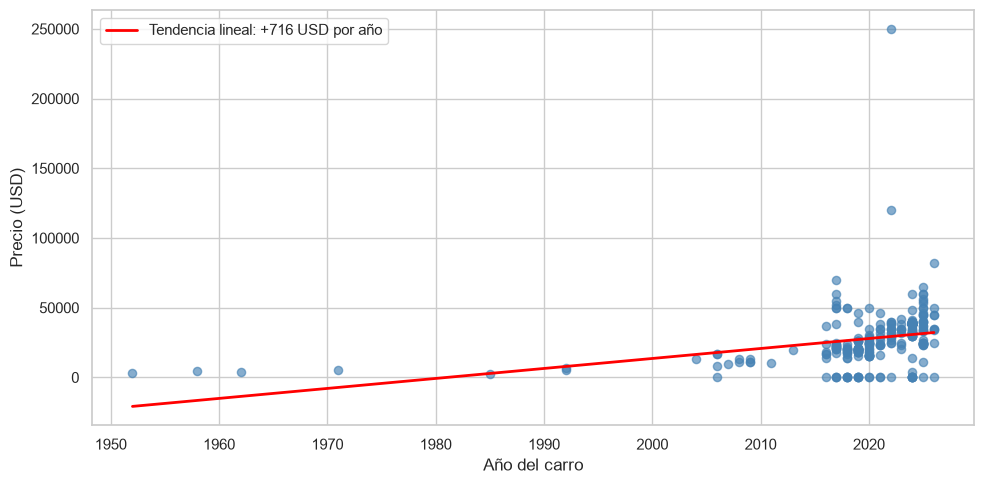

In [11]:
# 3.4 Precio vs. año del carro
por_anio = precios[precios["anio"] > 0]
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(por_anio["anio"], por_anio["precio_usd"], alpha=0.65, s=35, color="steelblue")
coef = np.polyfit(por_anio["anio"], por_anio["precio_usd"], 1)
xs = np.linspace(por_anio["anio"].min(), por_anio["anio"].max(), 100)
ax.plot(xs, np.polyval(coef, xs), color="red", lw=2,
        label=f"Tendencia lineal: +{coef[0]:,.0f} USD por año")
ax.set_xlabel("Año del carro")
ax.set_ylabel("Precio (USD)")
ax.legend()
plt.tight_layout()
plt.savefig(RAIZ / "reports" / "fig_04_precio_por_anio.png", dpi=130, bbox_inches="tight")
plt.show()

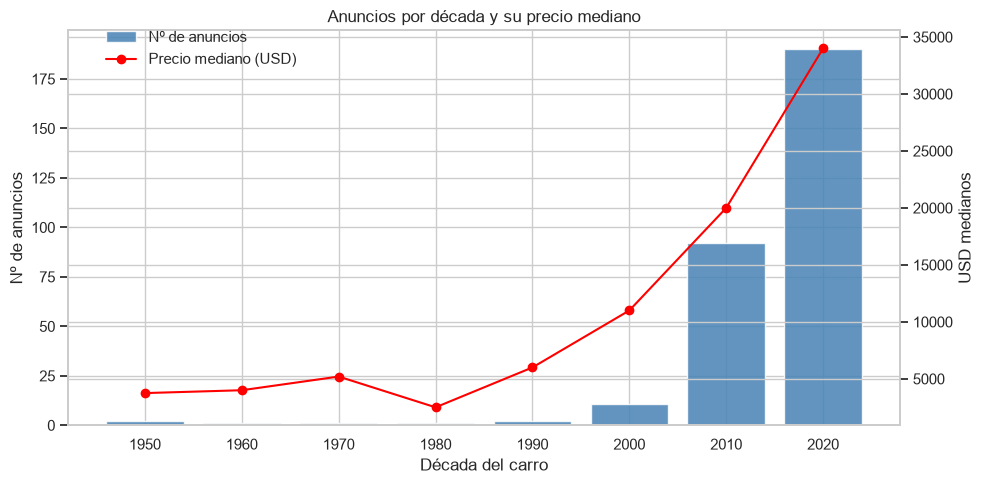

In [12]:
# 3.5 Anuncios y precio mediano por década
d = por_anio.copy()
d["decada"] = (d["anio"] // 10) * 10
agg = d.groupby("decada").agg(n=("precio_usd", "size"),
                              precio_med=("precio_usd", "median"))
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(agg.index.astype(str), agg["n"], color="steelblue", alpha=0.85,
       label="Nº de anuncios")
ax.set_xlabel("Década del carro"), ax.set_ylabel("Nº de anuncios")
ax2 = ax.twinx()
ax2.plot(agg.index.astype(str), agg["precio_med"], color="red", marker="o",
         label="Precio mediano (USD)")
ax2.set_ylabel("USD medianos")
ax.set_title("Anuncios por década y su precio mediano")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.95), frameon=False)
plt.tight_layout()
plt.savefig(RAIZ / "reports" / "fig_05_por_decada.png", dpi=130, bbox_inches="tight")
plt.show()

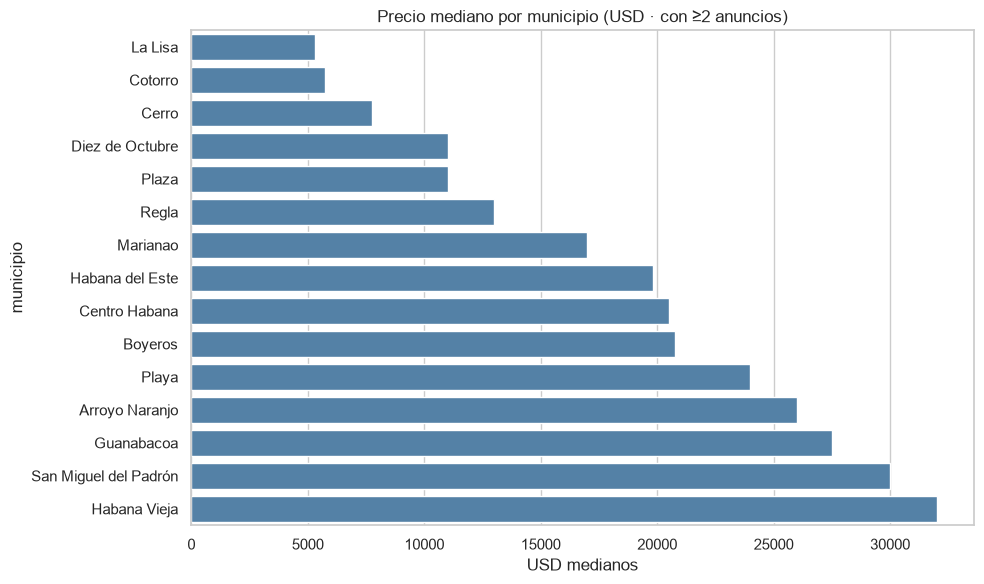

In [13]:
# 3.6 Precio mediano por municipio (con al menos 2 anuncios)
conteo = precios["municipio"].value_counts()
zonas = conteo[conteo >= 2].index
mpz = precios[precios["municipio"].isin(zonas)]\
    .groupby("municipio")["precio_usd"].median().sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=mpz.values, y=mpz.index, color="steelblue", ax=ax)
ax.set_title("Precio mediano por municipio (USD · con ≥2 anuncios)")
ax.set_xlabel("USD medianos")
plt.tight_layout()
plt.savefig(RAIZ / "reports" / "fig_06_precio_por_municipio.png", dpi=130, bbox_inches="tight")
plt.show()

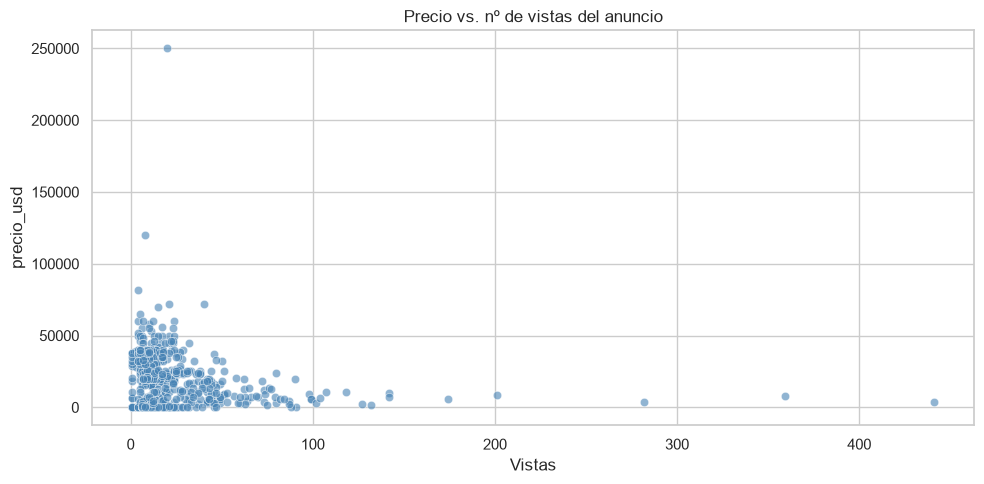

In [14]:
# 3.7 Precio vs. vistas del anuncio
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=precios, x="vistas", y="precio_usd",
                alpha=0.6, color="steelblue", ax=ax)
ax.set_title("Precio vs. nº de vistas del anuncio")
ax.set_xlabel("Vistas")
plt.tight_layout()
plt.savefig(RAIZ / "reports" / "fig_07_precio_vs_vistas.png", dpi=130, bbox_inches="tight")
plt.show()

## 4. Hallazgos

_Con los números reales de la muestra ampliada (600 anuncios, 555 con precio).
Respuestas preliminares a las preguntas Q1 (factores del precio) y Q3
(segmentos)._

1. **La oferta es mayoritariamente de carros modernos (Q3).** Hyundai lidera con
   137 anuncios (23%), seguida de Kia (33), Toyota (32), Nissan (31) y Lada
   (28). **301 de los 321 anuncios con año son posteriores a 2010** (94%); los
   clásicos (≤1990) son solo 6, el más antiguo de 1952.

2. **El precio es disperso (Q1): mediana de 19 500 USD.** El rango va de precios
   simbólicos (15 anuncios a 1 USD) a 250 000 USD (un BMW X6). Un 92% de los
   anuncios publica precio; los restantes son «a convenir». Con el criterio IQR
   hay 3 valores atípicos altos (Q3 + 1.5·IQR = 79 500 USD): un dongfeng a
   82 000 y dos BMW X6 a 120 000 y 250 000 USD.

3. **El año sigue siendo un factor fuerte (Q1).** La tendencia lineal sobre los
   300 anuncios con año y precio indica **~+716 USD por cada año adicional**
   (r = 0.30). El precio mediano pasa de ~11 000 USD en carros de los 2000–2010
   a ~34 000 USD en los de 2020+.

4. **Se distinguen segmentos por precio (Q3).** Medio-alto: Toyota (mediana
   38 000 USD), Nissan (32 000) y Kia (23 500); Hyundai, pese a ser la más
   anunciada, queda en 25 000 USD porque abarca mucha variedad de modelos.
   Económico/de trabajo: Lada (6 000 USD) y Daewoo (11 000). La zona pesa poco:
   Playa concentra 32% de la oferta (189 anuncios) con mediana 24 000 USD, por
   debajo de Arroyo Naranjo (26 000).

5. **La visibilidad no sigue al precio, y la muestra tiene límites.** Las vistas
   medianas son bajas (13) y la correlación vistas–precio es débil y negativa
   (r ≈ −0.20). El 35% (210) y el 46% (279) de los anuncios no reportan marca ni
   año (marcados como `año = 0` y excluidos solo de los análisis que usan año).
   La muestra es 600 de ~3 517 publicados: los resultados se formalizan con la
   regresión de la Fase 5.

In [15]:
# 4.1 Números clave para el informe
n = len(df_limpio)
con_precio = precios["precio_usd"].notna().sum()
print(f"Anuncios totales: {n}")
print(f"Con precio en USD: {con_precio} ({con_precio/n:.0%})")
print(f"Precio mediano: {precios['precio_usd'].median():,.0f} USD")
print(f"Precio medio:   {precios['precio_usd'].mean():,.0f} USD")
print(f"Anuncios con año: {(df_limpio['anio']>0).sum()} · sin marca: {(df_limpio['marca']=='no identificada').sum()}")
print(f"Marca más anunciada: {df_limpio['marca'].value_counts().index[0]}")
print(f"Municipio más representado: {df_limpio['municipio'].value_counts().index[0]}")
print(f"Vistas medianas: {precios['vistas'].median():,.0f}")

Anuncios totales: 600
Con precio en USD: 555 (92%)
Precio mediano: 19,500 USD
Precio medio:   20,646 USD
Anuncios con año: 321 · sin marca: 210
Marca más anunciada: no identificada
Municipio más representado: Playa
Vistas medianas: 13


## 5. Guardado del dataset procesado

Resultado limpio para la Fase 5 (modelo de precios) en
`data/processed/mercado_havana.csv`.

In [16]:
# 5.1 Seleccionar y ordenar columnas, guardar
columnas = ["fuente", "fecha", "ubicacion", "municipio", "marca", "modelo",
            "anio", "precio_original", "moneda", "precio_usd", "descripcion",
            "url", "anuncio_id", "vistas", "imagenes", "es_destacado",
            "actualizado_el"]
df_final = df_limpio.reindex(columns=columnas)
salida = RAIZ / "data" / "processed" / "mercado_havana.csv"
df_final.to_csv(salida, index=False, encoding="utf-8-sig")
print(f"Guardado: {salida} ({len(df_final)} filas)")
df_final.head()

Guardado: D:\Dany\ProyectoCD\data\processed\mercado_havana.csv (600 filas)


,fuente,fecha,ubicacion,municipio,marca,modelo,anio,precio_original,moneda,precio_usd,descripcion,url,anuncio_id,vistas,imagenes,es_destacado,actualizado_el
0,anuncio,2026-09-24,"La Habana, Playa",Playa,lada,2107,0,6800.0,USD,6800.0,Venta lada 2107,https://www.revolico.com/item/venta-lada-2107-...,57663364,1,0,False,2026-09-25T00:18:35.638Z
1,anuncio,2026-09-24,"La Habana, Arroyo Naranjo",Arroyo Naranjo,toyota,corolla automático gasolina,2018,18500.0,USD,18500.0,Toyota Corolla 2018 automático gasolina azul -...,https://www.revolico.com/item/toyota-corolla-2...,57663088,1,3,False,2026-09-24T23:58:17.615Z
2,anuncio,2026-09-24,"La Habana, Guanabacoa",Guanabacoa,lada,1600 único dueño,0,5000.0,USD,5000.0,Lada 1600. Único dueño. 5k,https://www.revolico.com/item/lada-1600-unico-...,57661916,13,4,False,2026-09-24T22:32:58.989Z
3,anuncio,2026-09-24,"La Habana, Guanabacoa",Guanabacoa,hyundai,ioniq 5,2024,38000.0,USD,38000.0,Hyundai IONIQ 5 2024,https://www.revolico.com/item/hyundai-ioniq-5-...,57661707,1,4,False,2026-09-24T22:17:40.552Z
4,anuncio,2026-09-24,"La Habana, Plaza",Plaza,no identificada,aprovecha,0,4200.0,USD,4200.0,Aprovecha,https://www.revolico.com/item/aprovecha-57661621,57661621,9,3,False,2026-09-24T22:10:59.643Z
